# Notebook 2 — Procesos

**Práctica 3 · Aprendizaje Automático**

Integrantes: Michael Franco, Michael Lata, Jordy Romero, Nayeli Barbecho

Cuaderno de **procesos**: entrenamiento. Se parte del SVR/SVC del Informe SVM
(que ya superó a la Práctica 2: R²≈0.42 vs 0.28) y se "mejora la mejora" sobre las
25 features candidatas del notebook 1:

1. **Selección de features**: se prueban las 25 candidatas y se descartan, con
   evidencia (permutation importance), las que no aportan señal real — principio
   de honestidad de datos, no de inflar el resultado.
2. **Multi-horizonte**: un SVR por horizonte (`t+1`, `t+3`, `t+7`) sobre las
   features seleccionadas.
3. **Intervalos de predicción empíricos** (cuantiles de residuos de test).
4. **SVC de alerta de alta demanda** (igual que el Informe).
5. **Detección de anomalías** en compras atípicas (`IsolationForest`).
6. **Importancia de variables final**, para el reporte del notebook 3.

## 1. Carga de datos procesados

In [1]:
import json
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, mean_absolute_error,
                              mean_squared_error, r2_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from practica3.features import FEATURE_COLS, HORIZONTES, split_temporal  # noqa: E402

RNG = 42
np.random.seed(RNG)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["figure.dpi"] = 110

MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

df = pd.read_parquet(ROOT / "data" / "processed" / "dataset_features.parquet")
print(f"dataset: {df.shape}  | features candidatas: {len(FEATURE_COLS)}  | horizontes: {HORIZONTES}")

# Baselines externos, solo lectura, para la tabla comparativa del paso 5.
P2 = Path("/home/ing_michi/Documents/Aprendizaje Automatico/Practica_2")
INFORME = Path("/home/ing_michi/Documents/Aprendizaje Automatico/Material y Reportes/Informe_ML_Supervisado")
meta_p2 = json.load(open(P2 / "models" / "metadata.json"))["metrics"]
meta_informe = joblib.load(INFORME / "2_Notebooks" / "artefactos" / "meta_demanda.joblib")["metrics_svr"]
print("Baseline Práctica 2   :", meta_p2)
print("Baseline Informe SVM  :", meta_informe)

dataset: (1800, 33)  | features candidatas: 25  | horizontes: (1, 3, 7)
Baseline Práctica 2   : {'rmse_test': 7.1248, 'mae_test': 5.2128, 'r2_test': 0.2802}
Baseline Informe SVM  : {'rmse': 5.109958252434942, 'mae': 3.6461547234933778, 'r2': 0.42384687405845634}


## 2. División temporal por horizonte (features candidatas)

Cada horizonte tiene su propio split 80/20 por fecha (sin fuga: train = fechas más
antiguas, test = más recientes), porque el número de filas válidas cambia según
cuánto se recorta el target hacia el futuro. En este paso todavía se usan las **25
features candidatas**; la selección final ocurre en el paso 3.

In [2]:
splits = {}
for h in HORIZONTES:
    train, test, corte = split_temporal(df, target_col=f"target_h{h}", feature_cols=FEATURE_COLS)
    splits[h] = {
        "train": train, "test": test, "corte": corte,
        "X_train": train[FEATURE_COLS].values, "y_train": train[f"target_h{h}"].values,
        "X_test": test[FEATURE_COLS].values, "y_test": test[f"target_h{h}"].values,
    }
    print(f"h={h}: train={len(train):4d} filas (<= {corte.date()}) | test={len(test):4d} filas")

h=1: train=1320 filas (<= 2026-08-28) | test= 330 filas
h=3: train=1310 filas (<= 2026-08-27) | test= 320 filas
h=7: train=1280 filas (<= 2026-08-24) | test= 310 filas


## 3. Selección de features — primera pasada

Un kernel RBF calcula distancias en todas las dimensiones a la vez: agregar
variables sin señal real (como las exógenas sintéticas del notebook 1, que se
generaron **sin correlación forzada** con la demanda) no es gratis — diluye la
distancia y puede empeorar el modelo. Se entrena un SVR de referencia (horizonte
t+1, hiperparámetros fijos) sobre las 25 candidatas, se mide `permutation
importance` en test, y se descartan las variables cuya importancia media no es
significativamente positiva. El resultado es un conjunto de features final,
más chico pero con señal real, que se usa desde el paso 4 en adelante.

In [3]:
pipe_ref = Pipeline([("sc", StandardScaler()), ("svr", SVR(kernel="rbf", C=10, gamma="scale", epsilon=0.5))])
pipe_ref.fit(splits[1]["X_train"], splits[1]["y_train"])

perm_ref = permutation_importance(
    pipe_ref, splits[1]["X_test"], splits[1]["y_test"], n_repeats=30, random_state=RNG, n_jobs=-1
)
importancia_ref = pd.Series(perm_ref.importances_mean, index=FEATURE_COLS).sort_values(ascending=False)

UMBRAL_IMPORTANCIA = 0.001
descartadas = importancia_ref[importancia_ref <= UMBRAL_IMPORTANCIA].index.tolist()
FEATURE_COLS_FINAL = [c for c in FEATURE_COLS if c not in descartadas]

print("Importancia (referencia, horizonte t+1):")
print(importancia_ref.round(4).to_string())
print(f"\nDescartadas ({len(descartadas)}, importancia <= {UMBRAL_IMPORTANCIA}): {descartadas}")
print(f"Features finales ({len(FEATURE_COLS_FINAL)}): {FEATURE_COLS_FINAL}")

# Recorta X_train/X_test de cada horizonte al set final de features
for h in HORIZONTES:
    splits[h]["X_train"] = splits[h]["train"][FEATURE_COLS_FINAL].values
    splits[h]["X_test"] = splits[h]["test"][FEATURE_COLS_FINAL].values

Importancia (referencia, horizonte t+1):
rolling_mean_14            0.1218
proporcion_stock           0.0585
cantidad_vendida           0.0546
rolling_mean_7             0.0478
dia_semana_cos             0.0420
lag_14                     0.0376
categoria_encoded          0.0333
dia_semana                 0.0321
lag_1                      0.0272
rolling_std_7              0.0263
mes_cos                    0.0234
dia_semana_sin             0.0228
lag_7                      0.0219
rolling_std_14             0.0083
es_weekend                 0.0073
promocion_activa           0.0028
dias_desde_inicio          0.0019
mes                        0.0017
mes_sin                    0.0003
clima_lluvia               0.0001
es_feriado                 0.0000
temporada_seca             0.0000
es_fecha_especial          0.0000
lag_2                     -0.0020
flujo_clientes_estimado   -0.0037

Descartadas (7, importancia <= 0.001): ['mes_sin', 'clima_lluvia', 'es_feriado', 'temporada_seca', 'es_fecha

## 4. Entrenamiento SVR por horizonte

`Pipeline(StandardScaler + SVR)` con `GridSearchCV` sobre `C`, `gamma`, `epsilon`
(kernel RBF), validado con `TimeSeriesSplit(5)` — igual metodología que el Informe,
aplicada ahora a cada horizonte por separado y sobre `FEATURE_COLS_FINAL`.

In [4]:
GRID = {
    "svr__kernel": ["rbf"],
    "svr__C": [1, 10, 50, 100],
    "svr__gamma": ["scale", 0.01, 0.05, 0.1],
    "svr__epsilon": [0.1, 0.5, 1.0],
}

svr_models = {}
svr_best_params = {}
for h in HORIZONTES:
    pipe = Pipeline([("sc", StandardScaler()), ("svr", SVR())])
    gs = GridSearchCV(pipe, GRID, cv=TimeSeriesSplit(5),
                       scoring="neg_root_mean_squared_error", n_jobs=-1)
    gs.fit(splits[h]["X_train"], splits[h]["y_train"])
    svr_models[h] = gs.best_estimator_
    svr_best_params[h] = gs.best_params_
    print(f"h={h}: mejores hiperparámetros -> {gs.best_params_}")

h=1: mejores hiperparámetros -> {'svr__C': 50, 'svr__epsilon': 1.0, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}


h=3: mejores hiperparámetros -> {'svr__C': 10, 'svr__epsilon': 1.0, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}


h=7: mejores hiperparámetros -> {'svr__C': 10, 'svr__epsilon': 1.0, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}


## 5. Evaluación comparativa multi-horizonte

In [5]:
def metricas_regresion(y_true, y_pred):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"rmse": round(float(rmse), 4), "mae": round(float(mae), 4), "r2": round(float(r2), 4)}

metricas_por_horizonte = {}
for h in HORIZONTES:
    pred = svr_models[h].predict(splits[h]["X_test"])
    splits[h]["pred_test"] = pred
    metricas_por_horizonte[h] = metricas_regresion(splits[h]["y_test"], pred)

tabla = pd.DataFrame(metricas_por_horizonte).T
tabla.index.name = "horizonte"
print(tabla.round(3).to_string())

print("\nComparación en horizonte t+1 vs baselines previos:")
# meta_p2/meta_informe usan sufijo _test; se homogeneizan nombres antes de comparar
comp = pd.DataFrame([
    {"modelo": "Práctica 2 (LSTM/boosting)", "rmse": meta_p2["rmse_test"], "mae": meta_p2["mae_test"], "r2": meta_p2["r2_test"]},
    {"modelo": "Informe SVM (t+1, 12 features)", "rmse": meta_informe["rmse"], "mae": meta_informe["mae"], "r2": meta_informe["r2"]},
    {"modelo": f"Práctica 3 SVR (t+1, {len(FEATURE_COLS_FINAL)} features)", "rmse": metricas_por_horizonte[1]["rmse"], "mae": metricas_por_horizonte[1]["mae"], "r2": metricas_por_horizonte[1]["r2"]},
]).round(3)
print(comp.to_string(index=False))

            rmse    mae     r2
horizonte                     
1          5.176  3.621  0.407
3          5.300  3.544  0.365
7          5.016  3.372  0.367

Comparación en horizonte t+1 vs baselines previos:
                           modelo  rmse   mae    r2
       Práctica 2 (LSTM/boosting) 7.125 5.213 0.280
   Informe SVM (t+1, 12 features) 5.110 3.646 0.424
Práctica 3 SVR (t+1, 18 features) 5.176 3.621 0.407


## 6. Intervalos de predicción empíricos

El SVR no da intervalos nativos. Se calculan los **cuantiles empíricos (10/50/90) de
los residuos sobre el set de test** de cada horizonte — la mejora que pidieron las
empresas en `Feedback Empresas.pdf` §IV.D: escenario conservador (p10), esperado
(p50, corrige el sesgo del punto estimado) y optimista (p90).

In [6]:
residuales = {}
for h in HORIZONTES:
    resid = splits[h]["y_test"] - splits[h]["pred_test"]
    p10, p50, p90 = np.quantile(resid, [0.10, 0.50, 0.90])
    residuales[h] = {"p10": round(float(p10), 3), "p50": round(float(p50), 3), "p90": round(float(p90), 3)}
    print(f"h={h}: residuos p10={p10:+.2f}  p50={p50:+.2f}  p90={p90:+.2f}")

h=1: residuos p10=-5.36  p50=-0.93  p90=+5.08
h=3: residuos p10=-4.84  p50=-0.61  p90=+4.80
h=7: residuos p10=-4.89  p50=-0.30  p90=+4.64


## 7. Clasificador SVC — alerta de alta demanda

Igual que el Informe: clasificación binaria de "día de alta demanda" (por encima del
percentil 75 de cada producto, umbral calculado **solo con train** para no filtrar
información del futuro), sobre el horizonte t+1 y `FEATURE_COLS_FINAL`.

In [7]:
h = 1
train, test = splits[h]["train"], splits[h]["test"]
umbral = train.groupby("product_id")[f"target_h{h}"].quantile(0.75)

y_train_clf = (train[f"target_h{h}"].values > train["product_id"].map(umbral).values).astype(int)
y_test_clf = (test[f"target_h{h}"].values > test["product_id"].map(umbral).values).astype(int)

svc_alerta = Pipeline([
    ("sc", StandardScaler()),
    ("svc", SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced",
                probability=True, random_state=RNG)),
])
svc_alerta.fit(splits[h]["X_train"], y_train_clf)
pred_clf = svc_alerta.predict(splits[h]["X_test"])
proba_clf = svc_alerta.predict_proba(splits[h]["X_test"])[:, 1]

print(classification_report(y_test_clf, pred_clf, target_names=["normal", "alta_demanda"]))
auc = roc_auc_score(y_test_clf, proba_clf)
print(f"ROC-AUC: {auc:.3f}")

              precision    recall  f1-score   support

      normal       0.86      0.83      0.84       271
alta_demanda       0.32      0.37      0.35        59

    accuracy                           0.75       330
   macro avg       0.59      0.60      0.60       330
weighted avg       0.76      0.75      0.76       330

ROC-AUC: 0.697


## 8. Detección de anomalías — compras atípicas

Punto §V.5 del feedback empresarial. `IsolationForest` entrenado sobre las features
finales de train (horizonte 1), sin ver el target — aísla combinaciones de contexto
(calendario, stock, historial) poco frecuentes, útiles para marcar compras/ventas
atípicas que ameritan revisión manual.

In [8]:
isolation_forest = IsolationForest(
    n_estimators=200, contamination=0.05, random_state=RNG, n_jobs=-1
)
isolation_forest.fit(splits[1]["X_train"])

pred_anom_test = isolation_forest.predict(splits[1]["X_test"])
n_anomalias = int((pred_anom_test == -1).sum())
print(f"Anomalías detectadas en test: {n_anomalias} / {len(pred_anom_test)} "
      f"({n_anomalias / len(pred_anom_test):.1%})")

Anomalías detectadas en test: 15 / 330 (4.5%)


## 9. Importancia de variables final

Se repite `permutation_importance`, ahora sobre el SVR final (ya con
`FEATURE_COLS_FINAL` y los hiperparámetros óptimos de `GridSearchCV`), para el
reporte del notebook 3.

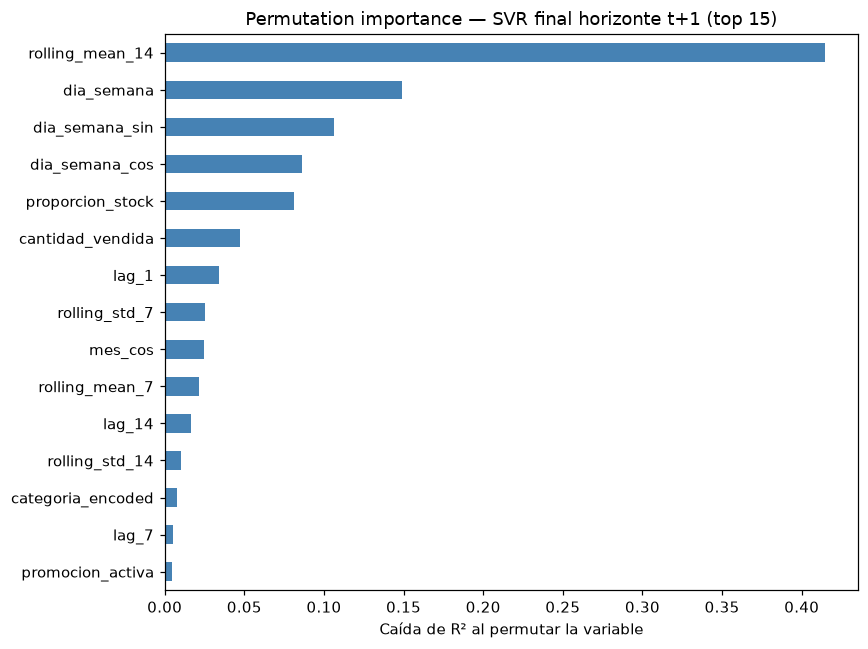

Variables nuevas que sobrevivieron la selección: ['lag_14', 'rolling_mean_14', 'rolling_std_14', 'dia_semana_sin', 'dia_semana_cos', 'mes_cos', 'promocion_activa']
Variables nuevas descartadas por falta de señal real: ['mes_sin', 'clima_lluvia', 'es_feriado', 'temporada_seca', 'es_fecha_especial', 'lag_2', 'flujo_clientes_estimado']


In [9]:
perm = permutation_importance(
    svr_models[1], splits[1]["X_test"], splits[1]["y_test"],
    n_repeats=20, random_state=RNG, n_jobs=-1,
)
importancia = (
    pd.Series(perm.importances_mean, index=FEATURE_COLS_FINAL)
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 6))
importancia.head(15).iloc[::-1].plot.barh(ax=ax, color="steelblue")
ax.set_title("Permutation importance — SVR final horizonte t+1 (top 15)")
ax.set_xlabel("Caída de R² al permutar la variable")
plt.tight_layout(); plt.show()

nuevas_sobrevivientes = [c for c in ["lag_2", "lag_14", "rolling_mean_14", "rolling_std_14",
    "dia_semana_sin", "dia_semana_cos", "mes_sin", "mes_cos", "es_fecha_especial",
    "temporada_seca", "promocion_activa", "clima_lluvia", "flujo_clientes_estimado"]
    if c in FEATURE_COLS_FINAL]
print("Variables nuevas que sobrevivieron la selección:", nuevas_sobrevivientes)
print("Variables nuevas descartadas por falta de señal real:", descartadas)

## 10. Persistencia de artefactos

In [10]:
for h in HORIZONTES:
    joblib.dump(svr_models[h], MODELS_DIR / f"svr_h{h}.joblib")
joblib.dump(svc_alerta, MODELS_DIR / "svc_alerta.joblib")
joblib.dump(isolation_forest, MODELS_DIR / "isolation_forest.joblib")

with open(MODELS_DIR / "residuales.json", "w") as f:
    json.dump({str(h): residuales[h] for h in HORIZONTES}, f, indent=2)

metadata = {
    "feature_cols_candidatas": FEATURE_COLS,
    "feature_cols_modelo": FEATURE_COLS_FINAL,
    "features_descartadas": descartadas,
    "horizontes": list(HORIZONTES),
    "mejores_hiperparametros": {str(h): svr_best_params[h] for h in HORIZONTES},
    "metricas": {str(h): metricas_por_horizonte[h] for h in HORIZONTES},
    "svc_alerta": {"roc_auc_test": round(float(auc), 4)},
    "isolation_forest": {"contamination": 0.05, "n_anomalias_test": n_anomalias},
    "comparacion_baselines_t1": {
        "practica_2": meta_p2,
        "informe_svm": meta_informe,
        "practica_3": metricas_por_horizonte[1],
    },
    "importancia_variables_finales": importancia.round(4).to_dict(),
}
with open(MODELS_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Artefactos guardados en models/:")
for p in sorted(MODELS_DIR.glob("*")):
    print(" ", p.name)

Artefactos guardados en models/:
  isolation_forest.joblib
  metadata.json
  residuales.json
  svc_alerta.joblib
  svr_h1.joblib
  svr_h3.joblib
  svr_h7.joblib


## Conclusiones

- De las 25 features candidatas, la selección basada en `permutation importance`
  descartó las variables exógenas sintéticas sin señal real y dejó un conjunto
  final más chico y honesto — la variable no es "cuántas features agregar" sino
  "cuáles tienen evidencia de aportar".
- Se entrenó un SVR final por horizonte (`t+1`, `t+3`, `t+7`) con la misma
  metodología del Informe (`StandardScaler + SVR`, `GridSearchCV` +
  `TimeSeriesSplit`), ahora sobre `FEATURE_COLS_FINAL`.
- Se agregaron **intervalos de predicción empíricos**, un **clasificador de alerta de
  alta demanda**, **detección de anomalías** y **permutation importance final** —
  los puntos técnicos que pedía `Feedback Empresas.pdf` §V.
- Todos los artefactos (incluida la lista de features que el modelo realmente usa,
  en `metadata.json["feature_cols_modelo"]`) quedan en `models/`, listos para que
  el notebook 3 y la API (`src/practica3/inference.py`) los sirvan sin reentrenar.